## 1. Load data and fix TotalCharges (11 blanks filled with 0, since tenure = 0)

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(df.shape)

(7043, 21)


In [2]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"] = df["TotalCharges"].fillna(0)
print(df["TotalCharges"].isnull().sum())  # should be 0



0


## 2. Drop customerID, check duplicates (22 kept), encode target

In [3]:
df = df.drop(columns=["customerID"])
print(df.duplicated().sum())

22


In [4]:
no_internet_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
                    "TechSupport", "StreamingTV", "StreamingMovies"]
for c in no_internet_cols:
    df[c] = df[c].replace("No internet service", "No")

df["MultipleLines"] = df["MultipleLines"].replace("No phone service", "No")

## 3. One-hot encode categorical features

In [5]:
cat_cols = df.select_dtypes(include="object").columns
df_encoded = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=int)
print(df_encoded.shape)
df_encoded.head()

(7043, 24)


C:\Users\ometh\AppData\Local\Temp\ipykernel_36048\2071578109.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include="object").columns


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_Yes,InternetService_Fiber optic,...,TechSupport_Yes,StreamingTV_Yes,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,Churn_Yes
0,0,1,29.85,29.85,0,1,0,0,0,0,...,0,0,0,0,0,1,0,1,0,0
1,0,34,56.95,1889.50,1,0,0,1,0,0,...,0,0,0,1,0,0,0,0,1,0
2,0,2,53.85,108.15,1,0,0,1,0,0,...,0,0,0,0,0,1,0,0,1,1
3,0,45,42.30,1840.75,1,0,0,0,0,0,...,1,0,0,1,0,0,0,0,0,0
4,0,2,70.70,151.65,0,0,0,1,0,1,...,0,0,0,0,0,1,0,1,0,1


In [6]:
df_encoded = df_encoded.rename(columns={"Churn_Yes": "Churn"})
df_encoded["Churn"].value_counts()


Churn
0    5174
1    1869
Name: count, dtype: int64

In [7]:
cat_cols = df.select_dtypes(exclude="number").columns

## 4. Train/test split (80/20, stratified)

In [8]:
from sklearn.model_selection import train_test_split

X = df_encoded.drop(columns=["Churn"])
y = df_encoded["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())  # both ~0.265

(5634, 23) (1409, 23)
0.2653532126375577 0.2654364797728886


## 5. Feature scaling (fit on train only)

In [9]:
from sklearn.preprocessing import StandardScaler

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

## 6. Baseline models (default settings, class_weight="balanced")

In [10]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score

knn = KNeighborsClassifier()
lr = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
rf = RandomForestClassifier(class_weight="balanced", random_state=42)

knn.fit(X_train_scaled, y_train)
lr.fit(X_train_scaled, y_train)
rf.fit(X_train, y_train)

models = {
    "KNN": (knn, X_test_scaled),
    "Logistic Regression": (lr, X_test_scaled),
    "Random Forest": (rf, X_test),
}
for name, (model, X_t) in models.items():
    pred = model.predict(X_t)
    proba = model.predict_proba(X_t)[:, 1]
    print(f"=== {name} ===")
    print(classification_report(y_test, pred))
    print("ROC-AUC:", round(roc_auc_score(y_test, proba), 3), "\n")

=== KNN ===
              precision    recall  f1-score   support

           0       0.84      0.84      0.84      1035
           1       0.55      0.55      0.55       374

    accuracy                           0.76      1409
   macro avg       0.70      0.70      0.70      1409
weighted avg       0.76      0.76      0.76      1409

ROC-AUC: 0.792 

=== Logistic Regression ===
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.51      0.79      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

ROC-AUC: 0.842 

=== Random Forest ===
              precision    recall  f1-score   support

           0       0.86      0.82      0.84      1035
           1       0.57      0.64      0.60       374

    accuracy                           0.77      1409
   macro avg       0.71      0.7

In [11]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

rows = []
for name, (model, X_t) in models.items():
    pred = model.predict(X_t)
    proba = model.predict_proba(X_t)[:, 1]
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
    })

baseline_df = pd.DataFrame(rows).round(3)
baseline_df

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,KNN,0.763,0.554,0.551,0.552,0.792
1,Logistic Regression,0.740,0.507,0.786,0.616,0.842
2,Random Forest,0.774,0.566,0.639,0.601,0.826


## 7. Hyperparameter tuning (GridSearchCV, 5-fold CV, scored on F1)

In [12]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

param_grids = {
    "KNN": (KNeighborsClassifier(),
            {"n_neighbors": [3, 5, 7, 9, 11, 15, 21],
             "weights": ["uniform", "distance"],
             "metric": ["euclidean", "manhattan"]},
            X_train_scaled),
    "Logistic Regression": (LogisticRegression(class_weight="balanced", solver="liblinear", max_iter=1000, random_state=42),
            {"C": [0.01, 0.1, 1, 10, 100],
             "penalty": ["l1", "l2"]},
            X_train_scaled),
    "Random Forest": (RandomForestClassifier(class_weight="balanced", random_state=42),
            {"n_estimators": [100, 200, 300],
             "max_depth": [5, 10, 20, None],
             "min_samples_split": [2, 5, 10]},
            X_train),
}

best_models = {}
for name, (estimator, grid, X_tr) in param_grids.items():
    search = GridSearchCV(estimator, grid, scoring="f1", cv=cv, n_jobs=-1)
    search.fit(X_tr, y_train)
    best_models[name] = search.best_estimator_
    print(f"=== {name} ===")
    print("Best params:", search.best_params_)
    print("Best CV F1:", round(search.best_score_, 3), "\n")

=== KNN ===
Best params: {'metric': 'euclidean', 'n_neighbors': 21, 'weights': 'uniform'}
Best CV F1: 0.596 



c:\Users\ometh\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


=== Logistic Regression ===
Best params: {'C': 0.1, 'penalty': 'l2'}
Best CV F1: 0.632 

=== Random Forest ===
Best params: {'max_depth': 10, 'min_samples_split': 10, 'n_estimators': 300}
Best CV F1: 0.637 



In [13]:
knn_grid = {
    "n_neighbors": [15, 21, 27, 33, 41, 51],
    "weights": ["uniform", "distance"],
    "metric": ["euclidean", "manhattan"],
}
knn_search = GridSearchCV(KNeighborsClassifier(), knn_grid, scoring="f1", cv=cv, n_jobs=-1)
knn_search.fit(X_train_scaled, y_train)

print("Best params:", knn_search.best_params_)
print("Best CV F1:", round(knn_search.best_score_, 3))

best_models["KNN"] = knn_search.best_estimator_

Best params: {'metric': 'manhattan', 'n_neighbors': 41, 'weights': 'uniform'}
Best CV F1: 0.606


## 8. Baseline vs tuned comparison on the test set

In [14]:
tuned_sets = {
    "KNN": X_test_scaled,
    "Logistic Regression": X_test_scaled,
    "Random Forest": X_test,
}

rows = []
for name, X_t in tuned_sets.items():
    model = best_models[name]
    pred = model.predict(X_t)
    proba = model.predict_proba(X_t)[:, 1]
    rows.append({
        "Model": name + " (tuned)",
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
    })

tuned_df = pd.DataFrame(rows).round(3)
comparison = pd.concat([baseline_df, tuned_df], ignore_index=True)
comparison


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,KNN,0.763,0.554,0.551,0.552,0.792
1,Logistic Regression,0.740,0.507,0.786,0.616,0.842
2,Random Forest,0.774,0.566,0.639,0.601,0.826
3,KNN (tuned),0.790,0.609,0.583,0.596,0.831
4,Logistic Regression (tuned),0.744,0.511,0.783,0.619,0.841
5,Random Forest (tuned),0.757,0.528,0.783,0.631,0.844


Tuning clearly helped KNN and Random Forest (higher F1 and ROC-AUC); Logistic Regression was already near its ceiling. Random Forest and Logistic Regression catch the same 293 churners, RF raises fewer false alarms.

## 9. Confusion matrices and ROC curves

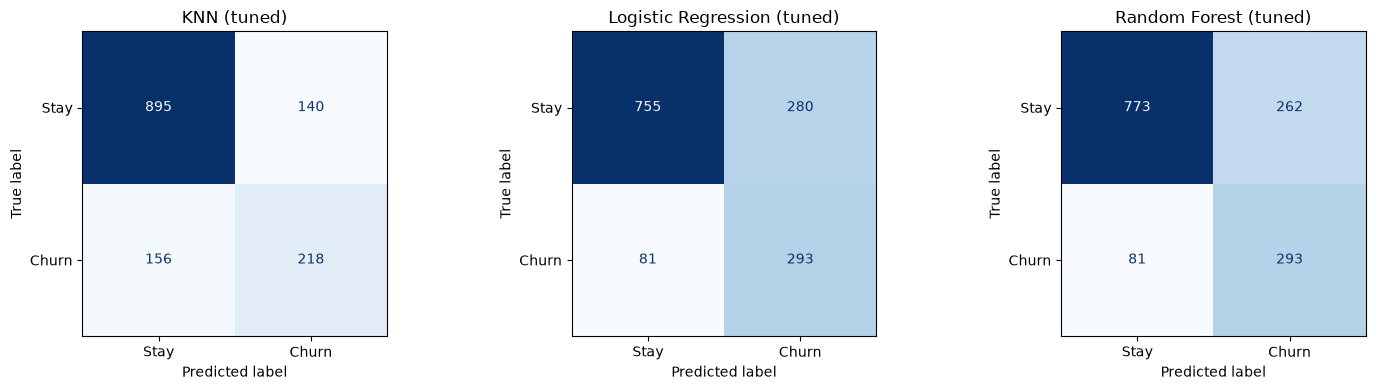

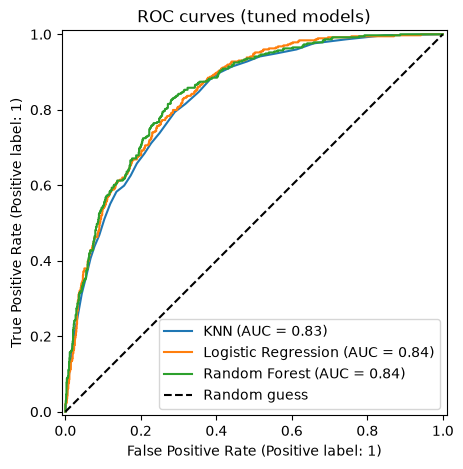

In [15]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

# Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, X_t) in zip(axes, tuned_sets.items()):
    ConfusionMatrixDisplay.from_estimator(
        best_models[name], X_t, y_test, ax=ax,
        display_labels=["Stay", "Churn"], cmap="Blues", colorbar=False
    )
    ax.set_title(name + " (tuned)")
plt.tight_layout()
plt.show()

# ROC curves
fig, ax = plt.subplots(figsize=(6, 5))
for name, X_t in tuned_sets.items():
    RocCurveDisplay.from_estimator(best_models[name], X_t, y_test, ax=ax, name=name)
ax.plot([0, 1], [0, 1], "k--", label="Random guess")
ax.set_title("ROC curves (tuned models)")
ax.legend()
plt.show()

## 10. Feature importance

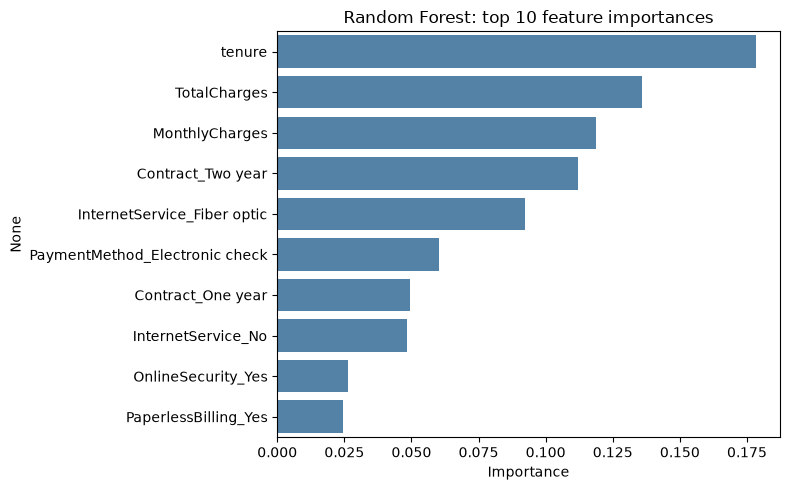

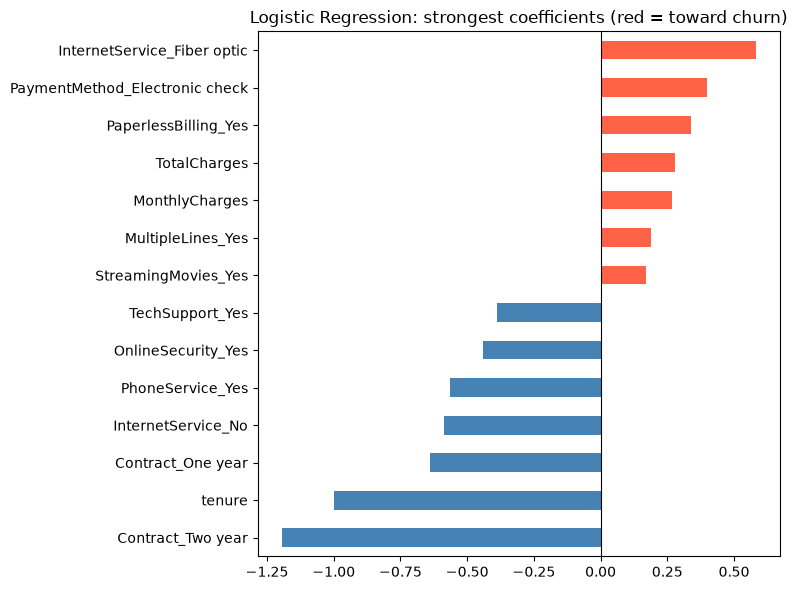

In [16]:
import seaborn as sns

# Random Forest importance (top 10)
rf_best = best_models["Random Forest"]
imp = pd.Series(rf_best.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 5))
sns.barplot(x=imp.values, y=imp.index, color="steelblue")
plt.title("Random Forest: top 10 feature importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

# Logistic Regression coefficients (7 strongest each way)
lr_best = best_models["Logistic Regression"]
coef = pd.Series(lr_best.coef_[0], index=X_train.columns).sort_values()
top_coef = pd.concat([coef.head(7), coef.tail(7)])

plt.figure(figsize=(8, 6))
top_coef.plot(kind="barh", color=["tomato" if v > 0 else "steelblue" for v in top_coef])
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Logistic Regression: strongest coefficients (red = toward churn)")
plt.tight_layout()
plt.show()

## 11. Fairness check by gender and senior citizen

In [17]:
rf_pred = best_models["Random Forest"].predict(X_test)
lr_pred = best_models["Logistic Regression"].predict(X_test_scaled)

groups = {
    "SeniorCitizen": {0: "Not senior", 1: "Senior"},
    "gender_Male": {0: "Female", 1: "Male"},
}

rows = []
for model_name, pred in [("Random Forest", rf_pred), ("Logistic Regression", lr_pred)]:
    for col, labels in groups.items():
        for val, label in labels.items():
            mask = (X_test[col] == val).values
            rows.append({
                "Model": model_name,
                "Group": label,
                "Size": mask.sum(),
                "Actual churn rate": round(y_test[mask].mean(), 3),
                "Predicted churn rate": round(pred[mask].mean(), 3),
                "Recall": round(recall_score(y_test[mask], pred[mask]), 3),
                "Precision": round(precision_score(y_test[mask], pred[mask]), 3),
            })

pd.DataFrame(rows)

,Model,Group,Size,Actual churn rate,Predicted churn rate,Recall,Precision
0,Random Forest,Not senior,1187,0.233,0.348,0.746,0.499
1,Random Forest,Senior,222,0.441,0.640,0.888,0.613
2,Random Forest,Female,687,0.281,0.392,0.751,0.539
3,Random Forest,Male,722,0.251,0.396,0.818,0.517
4,Logistic Regression,Not senior,1187,0.233,0.356,0.732,0.479
5,Logistic Regression,Senior,222,0.441,0.680,0.929,0.603
6,Logistic Regression,Female,687,0.281,0.408,0.777,0.536
7,Logistic Regression,Male,722,0.251,0.406,0.790,0.488


Gender shows no meaningful disparity. Seniors are flagged at a higher rate (partly because they genuinely churn more); compare their false alarm rate above.

In [18]:
from sklearn.metrics import confusion_matrix

rows = []
for model_name, pred in [("Random Forest", rf_pred), ("Logistic Regression", lr_pred)]:
    for col, labels in groups.items():
        for val, label in labels.items():
            mask = (X_test[col] == val).values
            tn, fp, fn, tp = confusion_matrix(y_test[mask], pred[mask]).ravel()
            rows.append({
                "Model": model_name,
                "Group": label,
                "False alarm rate (FPR)": round(fp / (fp + tn), 3),
                "Missed churner rate (FNR)": round(fn / (fn + tp), 3),
            })

fairness_df = pd.DataFrame(rows)
fairness_df

,Model,Group,False alarm rate (FPR),Missed churner rate (FNR)
0,Random Forest,Not senior,0.227,0.254
1,Random Forest,Senior,0.444,0.112
2,Random Forest,Female,0.251,0.249
3,Random Forest,Male,0.255,0.182
4,Logistic Regression,Not senior,0.241,0.268
5,Logistic Regression,Senior,0.484,0.071
6,Logistic Regression,Female,0.263,0.223
7,Logistic Regression,Male,0.277,0.210


In [19]:
import os
os.makedirs("results", exist_ok=True)
comparison.to_csv("results/model_comparison.csv", index=False)
fairness_df.to_csv("results/fairness_check.csv", index=False)